# English → Urdu Translation with a Transformer
### A complete, beginner-friendly training notebook

This notebook is a clean, consistent version of your original notebook. It includes dataset loading, preprocessing, vocabulary creation, an encoder–decoder Transformer, training and validation loss, learning-rate scheduling, early stopping, saving the best model, and translation examples.

**Important:** high accuracy cannot be guaranteed by code alone. It depends on the size and quality of your English–Urdu parallel dataset, training time, and hardware. This notebook trains a small Transformer from scratch; a pretrained translation model will usually perform better on a small dataset.

**Expected CSV columns:** `english` and `urdu`. Put `eng_urdu_dataset.csv` in the same folder as this notebook, or in `/content/dataset_extracted/` when using Google Colab. You can also upload it when prompted.

## 1. Install/import libraries
Run cells from top to bottom. PyTorch, pandas and scikit-learn are commonly preinstalled in Colab; the install command covers missing packages.

In [ ]:
import os
import re
import glob
import math
import random
import copy
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type == "cpu":
    print("Tip: for faster training, use Google Colab Runtime > Change runtime type > T4 GPU, if available.")

Device: cuda


## 2. Find and load the dataset

The notebook searches common folders for `eng_urdu_dataset.csv`. If it cannot find the CSV, it asks you to upload a CSV or ZIP containing the CSV.

If your dataset uses different column names, change `SOURCE_COLUMN` and `TARGET_COLUMN` below.

In [ ]:
# Search common notebook and Colab folders
possible_files = []
for folder in [".", "/content", "/content/dataset_extracted", "/mnt/data"]:
    possible_files.extend(glob.glob(os.path.join(folder, "**", "eng_urdu_dataset.csv"), recursive=True))

csv_path = possible_files[0] if possible_files else None

if csv_path is None:
    try:
        from google.colab import files
        print("Upload eng_urdu_dataset.csv or a ZIP file that contains it.")
        uploaded = files.upload()
        for name in uploaded:
            if name.lower().endswith(".zip"):
                with zipfile.ZipFile(name, "r") as z:
                    z.extractall("dataset_extracted")
                found = glob.glob("dataset_extracted/**/eng_urdu_dataset.csv", recursive=True)
                if found:
                    csv_path = found[0]
                    break
            elif name.lower().endswith(".csv"):
                csv_path = name
                break
    except ImportError:
        pass

if csv_path is None:
    raise FileNotFoundError(
        "Dataset CSV not found. Place eng_urdu_dataset.csv beside this notebook, "
        "or upload the CSV/ZIP in Google Colab."
    )

print("Using dataset:", csv_path)
df = pd.read_csv(csv_path)
print("Columns:", list(df.columns))
display(df.head())

Upload eng_urdu_dataset.csv or a ZIP file that contains it.


Saving archive.zip to archive.zip
Using dataset: dataset_extracted/eng_urdu_dataset.csv
Columns: ['english', 'urdu']


,english,urdu
0,The incipient rebellion was crushed before it ...,اس سے پہلے کہ اس کے بڑھنے سے پہلے ہی ناگوار بغ...
1,i feel strong,میں مضبوط محسوس کرتا ہوں۔
2,zain is untrustworthy,زین ناقابل اعتبار ہے
3,i will move heaven and earth,میں آسمان اور زمین کو حرکت دوں گا۔
4,The fossilized footprints of a dinosaur provid...,ڈایناسور کے جیواشم کے نقشوں نے اس کی رفتار اور...


In [ ]:
SOURCE_COLUMN = "english"
TARGET_COLUMN = "urdu"

if SOURCE_COLUMN not in df.columns or TARGET_COLUMN not in df.columns:
    raise ValueError(
        f"Expected columns '{SOURCE_COLUMN}' and '{TARGET_COLUMN}'. "
        f"Found: {list(df.columns)}. Update SOURCE_COLUMN and TARGET_COLUMN."
    )

df = df[[SOURCE_COLUMN, TARGET_COLUMN]].dropna().copy()
df[SOURCE_COLUMN] = df[SOURCE_COLUMN].astype(str).str.strip()
df[TARGET_COLUMN] = df[TARGET_COLUMN].astype(str).str.strip()
df = df[(df[SOURCE_COLUMN] != "") & (df[TARGET_COLUMN] != "")]
df = df.drop_duplicates().reset_index(drop=True)

# Optional length filter removes very long/noisy pairs; adjust if your data needs it.
df = df[
    (df[SOURCE_COLUMN].str.len() <= 500) &
    (df[TARGET_COLUMN].str.len() <= 500)
].reset_index(drop=True)

print("Usable sentence pairs:", len(df))
print(df.sample(min(3, len(df)), random_state=SEED).to_string(index=False))

Usable sentence pairs: 36860
             english                          urdu
that is just her way         یہ صرف اس کا راستہ ہے
 i cooked him dinner میں نے اسے رات کا کھانا پکایا
   zain seemed happy            زین خوش لگ رہا تھا


## 3. Split the data into train and validation sets

The model learns from the training set. The validation set is held back to check whether it generalizes to sentences it has not trained on.

In [ ]:
train_df, val_df = train_test_split(
    df, test_size=0.10, random_state=SEED, shuffle=True
)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

train_eng = train_df[SOURCE_COLUMN].tolist()
train_urdu = train_df[TARGET_COLUMN].tolist()
val_eng = val_df[SOURCE_COLUMN].tolist()
val_urdu = val_df[TARGET_COLUMN].tolist()

print(f"Training pairs: {len(train_df):,}")
print(f"Validation pairs: {len(val_df):,}")

Training pairs: 33,174
Validation pairs: 3,686


## 4. Tokenization and vocabularies

This simple tokenizer splits English words and punctuation. For Urdu, it preserves Urdu words and punctuation too. A word not seen in training maps to `<unk>`. For stronger real-world results, a pretrained subword tokenizer is usually better.

In [ ]:
UNK_IDX, PAD_IDX, BOS_IDX, EOS_IDX = 0, 1, 2, 3
SPECIAL_TOKENS = ["<unk>", "<pad>", "<bos>", "<eos>"]

def tokenize(sentence):
    # Unicode-aware word/punctuation split; lowercase English/Latin text.
    return re.findall(r"\w+|[^\w\s]", str(sentence).lower(), flags=re.UNICODE)

class Vocabulary:
    def __init__(self, sentences, min_frequency=1, max_size=30000):
        from collections import Counter
        counts = Counter()
        for sentence in sentences:
            counts.update(tokenize(sentence))

        self.stoi = {token: i for i, token in enumerate(SPECIAL_TOKENS)}
        # Most frequent words first for a compact vocabulary
        for word, count in counts.most_common():
            if count < min_frequency or word in self.stoi:
                continue
            if max_size is not None and len(self.stoi) >= max_size:
                break
            self.stoi[word] = len(self.stoi)
        self.itos = {i: word for word, i in self.stoi.items()}

    def __len__(self):
        return len(self.stoi)

    def encode(self, sentence, max_tokens=100):
        tokens = tokenize(sentence)[:max_tokens]
        ids = [self.stoi.get(token, UNK_IDX) for token in tokens]
        return [BOS_IDX] + ids + [EOS_IDX]

    def decode(self, ids):
        words = []
        for idx in ids:
            idx = int(idx)
            if idx == EOS_IDX:
                break
            if idx in (PAD_IDX, BOS_IDX):
                continue
            words.append(self.itos.get(idx, "<unk>"))
        # Basic detokenization: remove spaces before punctuation
        text = " ".join(words)
        text = re.sub(r"\s+([،۔,.!?;:])", r"\1", text)
        return text

# Vocabularies are built from training sentences only to avoid validation leakage.
SRC_MAX_VOCAB = 30000
TGT_MAX_VOCAB = 30000
MAX_TOKENS = 100

src_vocab = Vocabulary(train_eng, min_frequency=1, max_size=SRC_MAX_VOCAB)
tgt_vocab = Vocabulary(train_urdu, min_frequency=1, max_size=TGT_MAX_VOCAB)

print("English vocabulary:", len(src_vocab))
print("Urdu vocabulary:", len(tgt_vocab))

English vocabulary: 14394
Urdu vocabulary: 11299


## 5. Dataset and batches

In [ ]:
class TranslationDataset(Dataset):
    def __init__(self, source_sentences, target_sentences):
        self.sources = source_sentences
        self.targets = target_sentences

    def __len__(self):
        return len(self.sources)

    def __getitem__(self, index):
        source_ids = src_vocab.encode(self.sources[index], MAX_TOKENS)
        target_ids = tgt_vocab.encode(self.targets[index], MAX_TOKENS)
        return torch.tensor(source_ids), torch.tensor(target_ids)

def collate_batch(batch):
    sources, targets = zip(*batch)
    # batch_first=True means [batch, sequence_length]
    sources = pad_sequence(sources, batch_first=True, padding_value=PAD_IDX)
    targets = pad_sequence(targets, batch_first=True, padding_value=PAD_IDX)
    return sources, targets

BATCH_SIZE = 64 if DEVICE.type == "cuda" else 32

train_loader = DataLoader(
    TranslationDataset(train_eng, train_urdu),
    batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_batch,
    pin_memory=(DEVICE.type == "cuda")
)
val_loader = DataLoader(
    TranslationDataset(val_eng, val_urdu),
    batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_batch,
    pin_memory=(DEVICE.type == "cuda")
)

src_batch, tgt_batch = next(iter(train_loader))
print("Source batch shape:", tuple(src_batch.shape))
print("Target batch shape:", tuple(tgt_batch.shape))

Source batch shape: (64, 22)
Target batch shape: (64, 27)


## 6. Build the encoder–decoder Transformer

The encoder reads the English sentence. The decoder predicts Urdu tokens one by one. A causal mask prevents the decoder from looking at future target tokens.

In [ ]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, dropout=0.1, max_len=2048):
        super().__init__()
        position = torch.arange(max_len, dtype=torch.float32).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2, dtype=torch.float32)
            * (-math.log(10000.0) / d_model)
        )
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0))  # [1, max_len, d_model]
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.dropout(x + self.pe[:, :x.size(1)])

class TranslationTransformer(nn.Module):
    def __init__(
        self, src_vocab_size, tgt_vocab_size,
        d_model=256, nhead=8, num_layers=3,
        dim_feedforward=512, dropout=0.1
    ):
        super().__init__()
        self.d_model = d_model
        self.src_embedding = nn.Embedding(src_vocab_size, d_model, padding_idx=PAD_IDX)
        self.tgt_embedding = nn.Embedding(tgt_vocab_size, d_model, padding_idx=PAD_IDX)
        self.positional = PositionalEncoding(d_model, dropout)

        self.transformer = nn.Transformer(
            d_model=d_model,
            nhead=nhead,
            num_encoder_layers=num_layers,
            num_decoder_layers=num_layers,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True
        )
        self.output = nn.Linear(d_model, tgt_vocab_size)

    def forward(self, src, tgt_input):
        src_pad_mask = src.eq(PAD_IDX)
        tgt_pad_mask = tgt_input.eq(PAD_IDX)
        tgt_len = tgt_input.size(1)

        # True above diagonal blocks access to future tokens.
        causal_mask = torch.triu(
            torch.ones(tgt_len, tgt_len, device=tgt_input.device, dtype=torch.bool),
            diagonal=1
        )

        src_emb = self.positional(self.src_embedding(src) * math.sqrt(self.d_model))
        tgt_emb = self.positional(self.tgt_embedding(tgt_input) * math.sqrt(self.d_model))

        hidden = self.transformer(
            src_emb, tgt_emb,
            tgt_mask=causal_mask,
            src_key_padding_mask=src_pad_mask,
            tgt_key_padding_mask=tgt_pad_mask,
            memory_key_padding_mask=src_pad_mask
        )
        return self.output(hidden)

# d_model must be divisible by nhead.
model = TranslationTransformer(
    len(src_vocab), len(tgt_vocab),
    d_model=256, nhead=8, num_layers=3,
    dim_feedforward=512, dropout=0.1
).to(DEVICE)

print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")
print("Device:", DEVICE)

Parameters: 13,435,939
Device: cuda


## 7. Loss, optimizer, and training functions

Padding tokens do not count toward loss. Gradient clipping helps prevent unstable updates. Validation loss is calculated without updating the model.

In [ ]:
loss_function = nn.CrossEntropyLoss(ignore_index=PAD_IDX)

optimizer = torch.optim.AdamW(
    model.parameters(), lr=0.0003, betas=(0.9, 0.98), weight_decay=0.0001
)

def run_epoch(model, dataloader, training):
    model.train(training)
    total_loss = 0.0
    total_tokens = 0

    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for src, tgt in dataloader:
            src = src.to(DEVICE, non_blocking=True)
            tgt = tgt.to(DEVICE, non_blocking=True)

            # Teacher forcing: input omits final token; labels omit first token.
            tgt_input = tgt[:, :-1]
            tgt_answer = tgt[:, 1:]

            logits = model(src, tgt_input)
            loss = loss_function(
                logits.reshape(-1, logits.size(-1)),
                tgt_answer.reshape(-1)
            )

            if training:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()

            valid_tokens = tgt_answer.ne(PAD_IDX).sum().item()
            total_loss += loss.item() * max(valid_tokens, 1)
            total_tokens += valid_tokens

    return total_loss / max(total_tokens, 1)

# Quick shape/loss test before full training
src, tgt = next(iter(train_loader))
with torch.no_grad():
    sample_logits = model(src.to(DEVICE), tgt[:, :-1].to(DEVICE))
print("Logits shape:", tuple(sample_logits.shape))
print("Expected: [batch size, target length - 1, Urdu vocabulary size]")

Logits shape: (64, 19, 11299)
Expected: [batch size, target length - 1, Urdu vocabulary size]


## 8. Train the model

Defaults: up to 30 epochs, reduce the learning rate when validation loss plateaus, save the best validation checkpoint, and stop early if validation loss does not improve.

For a small dataset, a pretrained translation model may be much more accurate than training this model from scratch. If GPU memory runs out, reduce `BATCH_SIZE` to 16 and recreate the DataLoaders/model.

In [ ]:
EPOCHS = 30
PATIENCE = 5

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=2, min_lr=1e-6
)

history = {"train_loss": [], "val_loss": [], "lr": []}
best_val_loss = float("inf")
best_state = None
epochs_without_improvement = 0
CHECKPOINT_PATH = "best_english_urdu_transformer.pt"

for epoch in range(1, EPOCHS + 1):
    train_loss = run_epoch(model, train_loader, training=True)
    val_loss = run_epoch(model, val_loader, training=False)
    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["lr"].append(current_lr)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"train loss: {train_loss:.4f} | "
        f"val loss: {val_loss:.4f} | "
        f"lr: {current_lr:.6f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        torch.save({
            "model_state_dict": best_state,
            "src_vocab": src_vocab.stoi,
            "tgt_vocab": tgt_vocab.stoi,
            "d_model": model.d_model,
            "nhead": 8,
            "num_layers": 3,
            "dim_feedforward": 512,
            "max_tokens": MAX_TOKENS
        }, CHECKPOINT_PATH)
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping: validation loss did not improve.")
        break

if best_state is not None:
    model.load_state_dict(best_state)

print(f"Best validation loss: {best_val_loss:.4f}")
print("Best model saved to:", CHECKPOINT_PATH)

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:531: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


Epoch 01/30 | train loss: 5.0008 | val loss: 4.2195 | lr: 0.000300
Epoch 02/30 | train loss: 4.0358 | val loss: 3.7920 | lr: 0.000300
Epoch 03/30 | train loss: 3.6404 | val loss: 3.5354 | lr: 0.000300
Epoch 04/30 | train loss: 3.3392 | val loss: 3.3360 | lr: 0.000300
Epoch 05/30 | train loss: 3.0785 | val loss: 3.1183 | lr: 0.000300
Epoch 06/30 | train loss: 2.8467 | val loss: 2.9515 | lr: 0.000300
Epoch 07/30 | train loss: 2.6391 | val loss: 2.8371 | lr: 0.000300
Epoch 08/30 | train loss: 2.4456 | val loss: 2.7157 | lr: 0.000300
Epoch 09/30 | train loss: 2.2804 | val loss: 2.6016 | lr: 0.000300
Epoch 10/30 | train loss: 2.1304 | val loss: 2.5341 | lr: 0.000300
Epoch 11/30 | train loss: 1.9974 | val loss: 2.4662 | lr: 0.000300
Epoch 12/30 | train loss: 1.8760 | val loss: 2.4302 | lr: 0.000300
Epoch 13/30 | train loss: 1.7629 | val loss: 2.3860 | lr: 0.000300
Epoch 14/30 | train loss: 1.6648 | val loss: 2.3596 | lr: 0.000300
Epoch 15/30 | train loss: 1.5764 | val loss: 2.3336 | lr: 0.00

## 9. Plot training and validation loss
A healthy run usually shows both losses falling. If training loss falls but validation loss rises, that is a sign of overfitting.

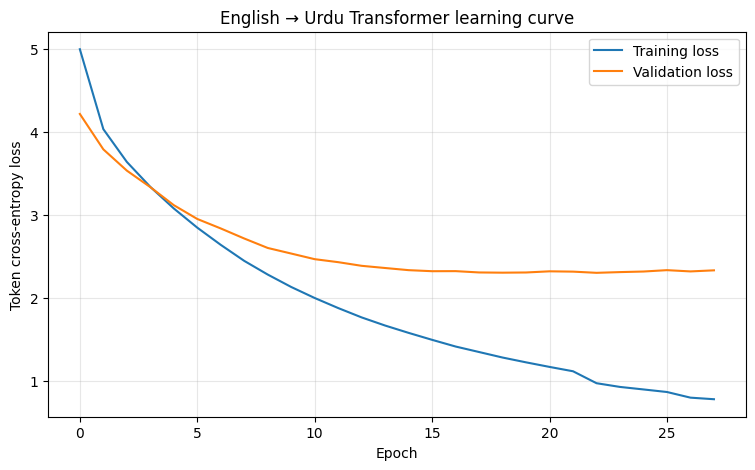

In [ ]:
plt.figure(figsize=(9, 5))
plt.plot(history["train_loss"], label="Training loss")
plt.plot(history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Token cross-entropy loss")
plt.title("English → Urdu Transformer learning curve")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 10. Translate a new English sentence

Greedy decoding chooses the highest-scoring next token at each step. It is simple, but beam search can sometimes produce better translations.

In [ ]:
def translate_english_to_urdu(sentence, max_new_tokens=100):
    model.eval()
    source_ids = src_vocab.encode(sentence, MAX_TOKENS)
    src = torch.tensor(source_ids, dtype=torch.long).unsqueeze(0).to(DEVICE)

    generated = [BOS_IDX]
    with torch.no_grad():
        for _ in range(max_new_tokens):
            tgt = torch.tensor(generated, dtype=torch.long).unsqueeze(0).to(DEVICE)
            logits = model(src, tgt)
            next_id = int(logits[0, -1].argmax(dim=-1).item())

            if next_id == EOS_IDX:
                break
            generated.append(next_id)

    return tgt_vocab.decode(generated[1:])

examples = [
    "How are you?",
    "What is your name?",
    "I am learning machine learning.",
    "Thank you very much."
]
for sentence in examples:
    print("English:", sentence)
    print("Urdu:   ", translate_english_to_urdu(sentence))
    print()

English: How are you?
Urdu:    آپ کیسے ہیں ؟

English: What is your name?
Urdu:    آپ کا نام کیا ہے ؟

English: I am learning machine learning.
Urdu:    میں مشین سیکھ رہا ہوں۔

English: Thank you very much.
Urdu:    آپ کا شکریہ



## 11. Compare predictions with reference translations
This checks several validation examples. Translation quality should be judged by meaning, not only by loss.

In [ ]:
for i in range(min(10, len(val_eng))):
    print(f"Example {i + 1}")
    print("English:   ", val_eng[i])
    print("Prediction:", translate_english_to_urdu(val_eng[i]))
    print("Reference: ", val_urdu[i])
    print("-" * 70)

Example 1
English:    that is just her way
Prediction: یہ صرف راستہ ہے
Reference:  یہ صرف اس کا راستہ ہے
----------------------------------------------------------------------
Example 2
English:    i cooked him dinner
Prediction: میں نے اس کا رات کا کھانا پکایا
Reference:  میں نے اسے رات کا کھانا پکایا
----------------------------------------------------------------------
Example 3
English:    zain seemed happy
Prediction: زین خوش لگ رہا تھا
Reference:  زین خوش لگ رہا تھا
----------------------------------------------------------------------
Example 4
English:    mary shaved her legs
Prediction: مریم نے اپنی ٹانگیں لی
Reference:  مریم نے اپنی ٹانگیں مونڈ دیں۔
----------------------------------------------------------------------
Example 5
English:    do you believe me now
Prediction: کیا تم اب مجھ پر یقین کرتے ہو
Reference:  کیا آپ اب مجھ پر یقین کرتے ہیں
----------------------------------------------------------------------
Example 6
English:    zain answer the door
Prediction: زین نے

## 12. Continue training or improve quality

- Use more clean, correctly aligned English–Urdu sentence pairs.
- Check duplicates and incorrect sentence pairs in the CSV.
- Train on a GPU and allow more epochs, but watch validation loss.
- If training loss stays high, the model may need more data, a longer training run, or tuning.
- If training loss falls while validation loss rises, use the best saved checkpoint and consider more data or stronger regularization.
- For substantially better translation quality, fine-tune a pretrained multilingual model such as NLLB or mT5 rather than relying on a small Transformer trained from scratch.

The saved checkpoint is `best_english_urdu_transformer.pt`. The vocabularies are stored in it too. Keep the same tokenizer and vocabulary when reusing the model.